# 05 — Második intelligenciaréteg: tematikus kategorizálás / Layer 2: thematic categorisation

HU: Az első réteg megmondja, **milyen** egy mondat (negatív / semleges / pozitív). A második réteg két szinten
mondja meg, **miről** és **pontosan mi miatt**:

```
mondat ──► [1. réteg] szentiment (B)              → negatív / semleges / pozitív
       ──► [2/a] aspektus-osztályozó (HRAST, BERT) → MIRŐL szól?   pl. bathroom
       ──► [2/b] altémák (beágyazás + fürtözés)    → MI A GOND?    pl. „nincs meleg víz”
```

| # | Lépés / Step | Mérés / Measurement | Dolgozat / Thesis |
|---|---|---|---|
| 1 | 2/a tanítás a HRAST-on / training on HRAST | aspektusonkénti F1 a HRAST-teszten, vs. kulcsszólista | 3.4, 3.5 |
| 2 | 2/a alkalmazás a Booking-mondatokra / applying to Booking | egyezés a kulcsszólistával | 3.5 |
| 3 | 2/b altémák aspektusonként / subtopics per aspect | NPMI-koherencia, diverzitás, stabilitás (ARI) | 3.4, 3.5 |
| 4 | Panasztérkép / complaint map | lift szegmensenként | 3.5 |
| 5 | Kézi ellenőrzés / manual check | témánkénti pontosság | 3.5 |

**Előfeltétel / Prerequisites:** a (B) modell (`results/models/approach_b_hrast`), a HRAST CSV a `data/raw/hrast/`
mappában, és `pip install sentence-transformers umap-learn`.
**Elemzési egység / Analysis unit:** tagmondat, a dicséret- és panaszmezőből KÜLÖN bontva / clause, split SEPARATELY
from the praise and complaint fields. GPU ajánlott (a 2/a tanítás kb. 10–15 perc).

## 1. Környezet és adatok / Environment and data

In [1]:
# HU: A notebooks/ mappából futunk, ezért a szülőmappát a path-hoz adjuk (src csomag).
# EN: We run from the notebooks/ folder, so the parent folder is added to the path (src package).
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import set_seed
from src.config import CFG, PATHS, SENTIMENT_COLORS, INK, APPROACHES, apply_plot_style
from src import data_loading as dl
from src import preprocessing as pp
from src import evaluation as ev
from src import descriptives as ds
from src import aspects as asp
from src import aspect_model as am
from src import topic_modeling as tm
from src import pipeline

# HU: Reprodukálhatóság + egységes ábrastílus. / EN: Reproducibility + uniform figure style.
set_seed()
PATHS.ensure()
apply_plot_style()
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 170)

# HU: ELEMZÉSI EGYSÉGEK: a dicséret- és a panaszmezőt KÜLÖN bontjuk tagmondatokra (pont, pontosvessző,
#     "but / however / although" mentén), így a kettő nem olvad egy "mondatba". Minden egységre lefut a
#     (B) modell is (kb. 5–10 perc, darabolva, folytatható).
# EN: ANALYSIS UNITS: the praise and the complaint field are split into clauses SEPARATELY (at full stops,
#     semicolons, "but / however / although"), so the two never merge into one "sentence". The (B) model
#     also runs on every unit (about 5–10 min, chunked, resumable).
from src import bert_labelling as bl
meta = ds.prepare_star_rating(dl.read_frame(pipeline.LABELLED))
units = pp.build_field_units(meta)
scorer_b = bl.TransformerScorer(str(PATHS.models / "approach_b_hrast"))
sent = bl.predict_units(units, "", "B", cache_name="B_field_units", scorer=scorer_b)

meta_cols = ["review_id", "score", "label_final", "accommodation_type", "accommodation_country",
             "guest_type", "accommodation_star_rating"]
sent = sent.merge(meta[[c for c in meta_cols if c in meta.columns]], on="review_id", how="left")
dl.write_frame(sent, PATHS.labels / "field_units_B")
print(f"{len(sent):,} units from {sent['review_id'].nunique():,} reviews")

# HU: Mezőpolaritás × (B)-címke: mennyire ért egyet a modell a vendég saját besorolásával?
# EN: Field polarity × (B) label: how far does the model agree with the guest's own classification?
display(pd.crosstab(sent["field_polarity"], sent["B_label"], normalize="index").round(3))

19:15:54 | INFO    | src.preprocessing | Field units: 85638 from 19969 reviews | by field: {'positive': 58897, 'negative': 26741}
19:16:18 | INFO    | src.bert_labelling | Loading model: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\models\approach_b_hrast (device: cuda, fp16: True)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

19:16:23 | INFO    | src.bert_labelling | Model type: 3class | labels: ['negative', 'neutral', 'positive']


85,638 units from 19,969 reviews


B_label,negative,neutral,positive
field_polarity,,,
negative,0.737,0.079,0.184
positive,0.067,0.029,0.904


## 2. 2/a — Aspektus-osztályozó a HRAST-on / Aspect classifier on HRAST

HU: Többcímkés BERT: aspektusonként egy igen/nem döntés (szigmoid). A ritka aspektusok nagyobb súlyt kapnak
(`pos_weight`), a döntési küszöböt aspektusonként a **validációs** halmazon hangoljuk, a végső mérés a **teszthalmazon**
történik — és ugyanott mérjük a kulcsszólistát is (alapvonal).

EN: Multi-label BERT: one yes/no decision per aspect (sigmoid). Rare aspects get a larger weight (`pos_weight`), the
decision threshold is tuned per aspect on the **validation** set, the final measurement is on the **test** set — where
the keyword list (baseline) is measured too.

In [2]:
hrast_raw = dl.load_hrast_raw()
asp_data, ASPECTS = am.prepare_hrast_aspects(hrast_raw)
counts = asp_data[ASPECTS].sum().sort_values(ascending=False).to_frame("sentences")
counts["share"] = (counts["sentences"] / len(asp_data)).round(4)
display(counts); ev.save_table(counts, "05_hrast_aspect_counts")

19:16:24 | INFO    | src.data_loading | HRAST loaded: hrast.csv — 23113 rows, columns: ['id', 'review', 'Unnamed: 2', 'positive', 'negative', 'neutral', 'Clean', 'Comfort', 'Facilities/Amenities', 'Location', 'Restaurant (dinner)', 'Staff', 'View (Balcony)', 'Breakfast', 'Room', 'Pool', 'Beach', 'Bathroom/Shower (toilet)', 'Bar', 'Bed', 'Parking', 'Noise', 'Reception-checkin', 'Lift', 'Value for money', 'Wi-Fi', 'Generic', 'Aspect']
19:16:24 | INFO    | src.aspect_model | HRAST aspect data: 23105 sentences, 21 aspects | without aspect: 0.0%


,sentences,share
room,5004,0.2166
location,4727,0.2046
staff,3800,0.1645
cleanliness,2926,0.1266
facilities,2923,0.1265
comfort,2561,0.1108
breakfast,2539,0.1099
bathroom,2344,0.1014
generic,1973,0.0854
noise,1604,0.0694


19:16:24 | INFO    | src.evaluation | Table saved: 05_hrast_aspect_counts.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/05_hrast_aspect_counts.csv')

Aspect model already trained — loading the saved test results.


,precision,recall,f1,support
room,0.7927,0.7906,0.7917,769
location,0.9348,0.9556,0.9451,675
staff,0.9193,0.9597,0.9391,546
cleanliness,0.9417,0.9417,0.9417,446
facilities,0.8479,0.8064,0.8266,470
comfort,0.8282,0.8258,0.8270,356
breakfast,0.9280,0.9704,0.9488,372
bathroom,0.9520,0.9242,0.9379,343
generic,0.7085,0.7864,0.7454,309
noise,0.9466,0.9323,0.9394,266


,support,keyword_precision,keyword_recall,keyword_f1,model_precision,model_recall,model_f1,f1_gain
aspect,,,,,,,,
room,769,0.5673,0.8986,0.6955,0.7927,0.7906,0.7917,0.0961
location,675,0.9282,0.9007,0.9143,0.9348,0.9556,0.9451,0.0308
staff,546,0.9022,0.8443,0.8723,0.9193,0.9597,0.9391,0.0668
facilities,470,0.5340,0.3511,0.4236,0.8479,0.8064,0.8266,0.4030
cleanliness,446,0.9332,0.7825,0.8512,0.9417,0.9417,0.9417,0.0905
breakfast,372,0.8589,0.9489,0.9017,0.9280,0.9704,0.9488,0.0471
bathroom,343,0.8963,0.9067,0.9014,0.9520,0.9242,0.9379,0.0364
noise,266,0.9755,0.7481,0.8468,0.9466,0.9323,0.9394,0.0926
value_for_money,136,0.6788,0.6838,0.6813,0.6894,0.8162,0.7475,0.0662


19:16:25 | INFO    | src.evaluation | Figure saved: 05_aspect_keyword_vs_model.png


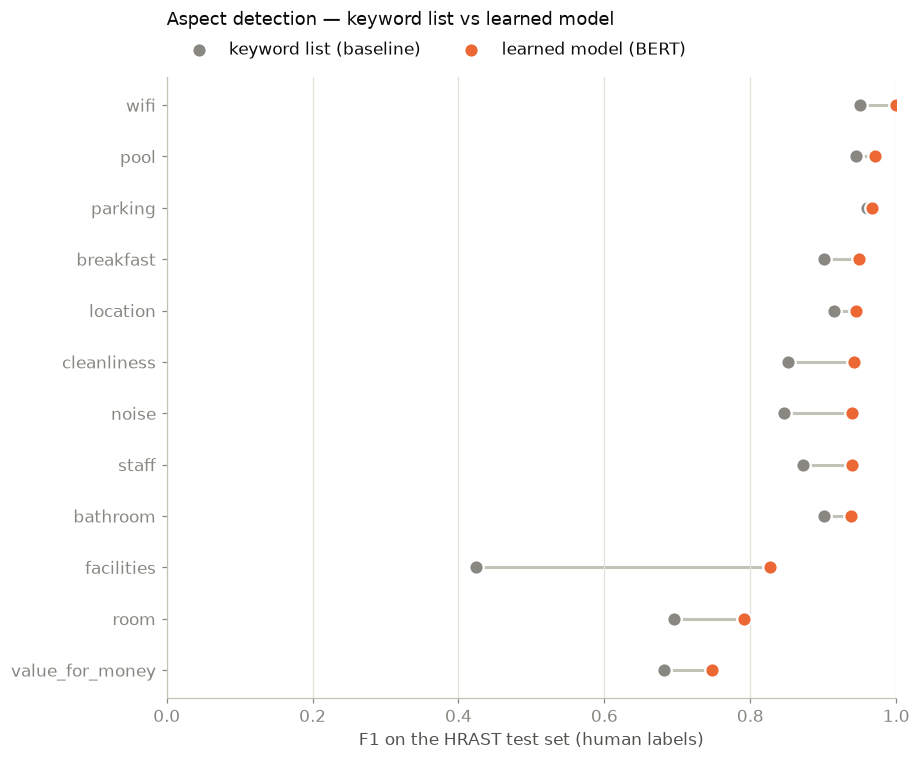

Mean F1 on the shared aspects — keyword: 0.829 | model: 0.913


In [3]:
# HU: Ha a modell már elkészült, nem tanítjuk újra (a mentett teszteredményt töltjük be).
# EN: If the model already exists it is not retrained (the saved test results are loaded).
if not (am.DEFAULT_MODEL_DIR / "thresholds.json").exists():
    result = am.train_aspect_model(asp_data, ASPECTS)
    report, comparison = result["test_report"], result["keyword_comparison"]
    ev.save_table(report, "05_aspect_model_test_report")
    ev.save_table(comparison, "05_aspect_keyword_vs_model")
else:
    print("Aspect model already trained — loading the saved test results.")
    report = pd.read_csv(PATHS.tables / "05_aspect_model_test_report.csv", index_col=0)
    comparison = pd.read_csv(PATHS.tables / "05_aspect_keyword_vs_model.csv", index_col=0)

display(report)
display(comparison)
am.plot_keyword_vs_model(comparison, save_as="05_aspect_keyword_vs_model"); plt.show()
print(f"Mean F1 on the shared aspects — keyword: {comparison['keyword_f1'].mean():.3f} | "
      f"model: {comparison['model_f1'].mean():.3f}")

## 3. 2/a alkalmazása a Booking-mondatokra / Applying 2/a to the Booking sentences

HU: Darabolt, folytatható futás (mint a címkézésnél). Itt nincs emberi címke, ezért a kulcsszólistával való
**egyezést** mérjük (konzisztencia), nem a pontosságot.
EN: Chunked, resumable run (as in labelling). There is no human label here, so we measure **agreement** with the
keyword list (consistency), not accuracy.

In [4]:
sent_asp = am.predict_aspects(sent, cache_name="aspects_field_units")
dl.write_frame(sent_asp, PATHS.labels / "field_units_aspects")
ASPECT_NAMES = am.aspect_names_in(sent_asp)

share = sent_asp[[f"asp_{a}" for a in ASPECT_NAMES]].mean().sort_values(ascending=False)
share.index = share.index.str.replace("asp_", "", regex=False)
display(share.round(4).to_frame("share of sentences"))
print(f"Sentences without any aspect: {(sent_asp['n_aspects'] == 0).mean():.1%}")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

19:16:27 | INFO    | src.aspect_model | Aspects predicted for 85638 sentences | without aspect: 3.3%


,share of sentences
location,0.2229
generic,0.2138
staff,0.1826
room,0.1708
facilities,0.1138
comfort,0.1070
cleanliness,0.1067
breakfast,0.1057
bathroom,0.0540
bed,0.0532


Sentences without any aspect: 3.3%


,mentions,mention_share,negative,neutral,positive,neg_lift,pos_lift
aspect,,,,,,,
lift,550,0.0064,0.7418,0.0545,0.2036,2.6846,0.2998
bathroom,4625,0.0540,0.5351,0.0359,0.4290,1.9366,0.6315
noise,3479,0.0406,0.4815,0.0287,0.4898,1.7424,0.7210
wifi,707,0.0083,0.4752,0.0311,0.4936,1.7199,0.7267
facilities,9748,0.1138,0.4088,0.0493,0.5419,1.4794,0.7977
reception,3024,0.0353,0.3532,0.0427,0.6042,1.2781,0.8894
value_for_money,3510,0.0410,0.3271,0.0533,0.6197,1.1836,0.9122
parking,1713,0.0200,0.3012,0.0665,0.6322,1.0901,0.9307
bar,793,0.0093,0.2913,0.0340,0.6747,1.0542,0.9932


19:16:28 | INFO    | src.evaluation | Table saved: 05_aspect_sentiment_model.csv
19:16:29 | INFO    | src.evaluation | Figure saved: 05_aspect_sentiment_model.png


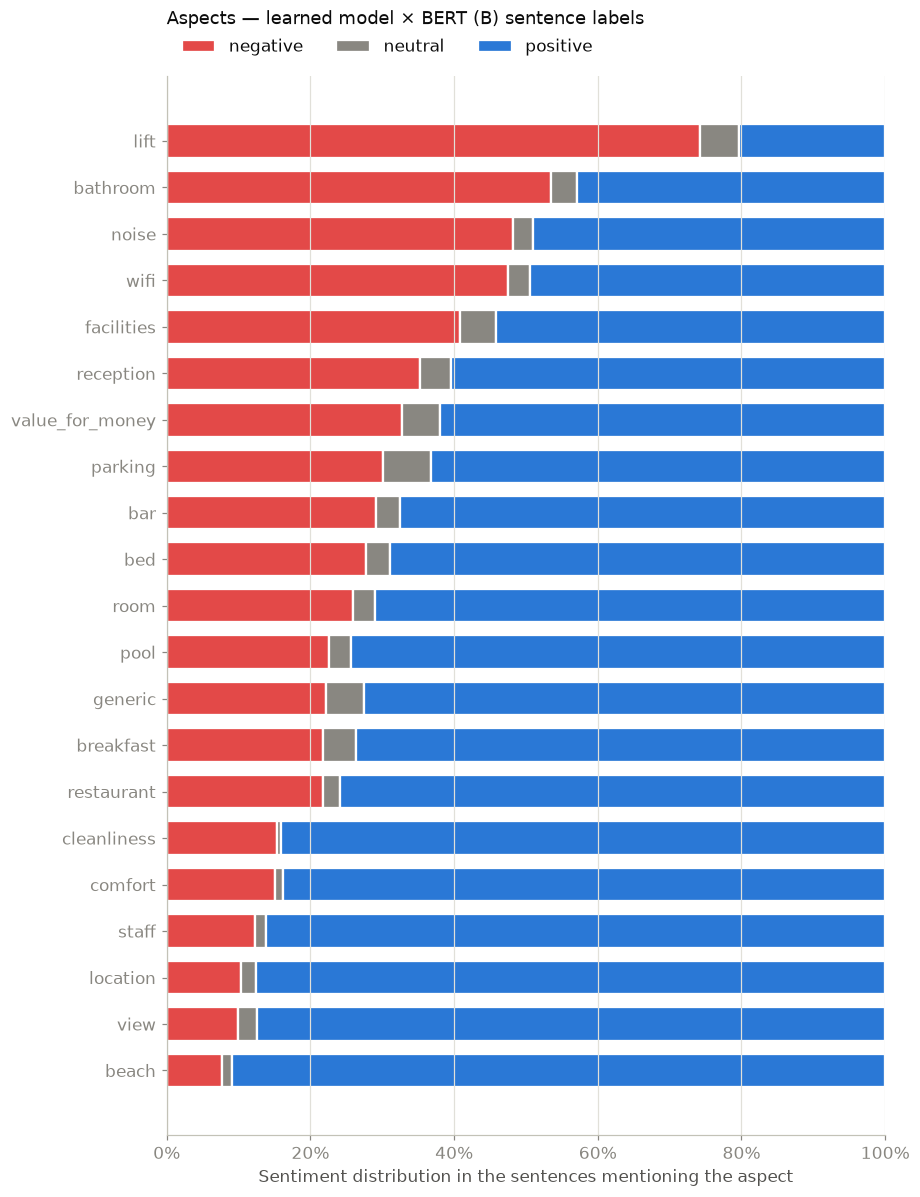

,share_model,share_keyword,agreement,cohen_kappa
aspect,,,,
location,0.2244,0.1769,0.9316,0.7875
staff,0.1835,0.1286,0.9282,0.7291
room,0.1699,0.2241,0.8745,0.6052
facilities,0.1144,0.0683,0.8892,0.3366
cleanliness,0.1063,0.0968,0.9835,0.9097
breakfast,0.1059,0.1191,0.9651,0.8253
bathroom,0.0535,0.0548,0.9834,0.8382
value_for_money,0.0410,0.0367,0.9815,0.7528
noise,0.0401,0.0328,0.9900,0.8572


19:16:35 | INFO    | src.evaluation | Table saved: 05_aspect_keyword_agreement_booking.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/05_aspect_keyword_agreement_booking.csv')

In [5]:
# HU: Aspektus × szentiment a TANULT aspektusokkal (vö. 04-es notebook: kulcsszavas változat).
# EN: Aspect × sentiment with the LEARNED aspects (cf. notebook 04: keyword version).
aspect_sent = asp.aspect_sentiment_table(sent_asp, label_col="B_label", aspects=ASPECT_NAMES,
                                         prefix="asp_", min_count=100)
display(aspect_sent); ev.save_table(aspect_sent, "05_aspect_sentiment_model")
asp.plot_aspect_sentiment(aspect_sent, "Aspects — learned model × BERT (B) sentence labels",
                          save_as="05_aspect_sentiment_model"); plt.show()

agreement = am.keyword_agreement(sent_asp.sample(min(50_000, len(sent_asp)), random_state=CFG.random_seed))
display(agreement); ev.save_table(agreement, "05_aspect_keyword_agreement_booking")

## 4. 2/b — Altémák aspektusonként / Subtopics per aspect

HU: A választott szentimentű (alapból **negatív**) mondatokon minden aspektusra külön témamodell: Sentence-BERT
beágyazás → UMAP → HDBSCAN → c-TF-IDF. A dicséretek altémáihoz állítsd `SENTIMENT = "positive"`-ra, és futtasd
újra innen (a fájlnevek a szentimentet is tartalmazzák).
EN: On sentences of the chosen sentiment (**negative** by default) a separate topic model per aspect: Sentence-BERT
embedding → UMAP → HDBSCAN → c-TF-IDF. For the subtopics of praise set `SENTIMENT = "positive"` and re-run from here
(file names include the sentiment).

In [15]:
SENTIMENT = "positive"
# HU: Az altéma-futás verziója (CFG.topic_version): minden alábbi kimenet nevében szerepel, így egy új
#     paraméterezés nem írja felül a korábbi (pl. v1) táblákat, ábrákat és kézi ellenőrzést.
# EN: Version of the subtopic run (CFG.topic_version): part of every output name below, so a new
#     parameter set does not overwrite earlier (e.g. v1) tables, figures and the manual check.
TAG = f"{SENTIMENT}_{CFG.topic_version}"
# HU: Kettős szűrés: a vendég a PANASZ-mezőbe írta, ÉS a (B) modell is negatívnak olvassa
#     (így kiesnek a panaszmezőbe írt "nothing, all perfect" típusú egységek).
# EN: Double filter: the guest wrote it into the COMPLAINT field AND the (B) model also reads it as
#     negative (this drops "nothing, all perfect" type units written into the complaint field).
subset = sent_asp[(sent_asp["field_polarity"] == SENTIMENT) & (sent_asp["B_label"] == SENTIMENT)
                  & (sent_asp["n_aspects"] > 0)].reset_index(drop=True)
print(f"{len(subset):,} {SENTIMENT} units with at least one aspect")

embeddings = tm.embed_sentences(subset["sentence"], cache_name=f"emb_{SENTIMENT}_units")

# HU: NEM-PANASZ egységek kiszűrése ("nothing", "no complaints", "all was perfect", "not the hotel's
#     fault"). A beágyazás a szűrés ELŐTT készül, így a cache érvényes marad; a sorokat utána
#     választjuk ki mindkettőből. Csak a negatív oldalon alkalmazzuk.
# EN: Remove NON-COMPLAINT units ("nothing", "no complaints", "all was perfect", "not the hotel's
#     fault"). The embedding is made BEFORE filtering, so the cache stays valid; rows are selected from
#     both afterwards. Applied on the negative side only.
if SENTIMENT == "negative":
    junk = pp.non_complaint_mask(subset["sentence"]).to_numpy()
    removed = subset.loc[junk, "sentence"].str.lower().str.strip(" .!").value_counts()
    print(f"Non-complaint units removed: {junk.sum():,} ({junk.mean():.1%})")
    display(removed.head(15).to_frame("count"))
    ev.save_table(removed.head(200).to_frame("count"), f"05_{TAG}_removed_non_complaints")
    subset, embeddings = subset.loc[~junk].reset_index(drop=True), embeddings[~junk]
print(f"{len(subset):,} units | embeddings: {embeddings.shape}")

52,612 positive units with at least one aspect


14:45:18 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/modules.json "HTTP/1.1 307 Temporary Redirect"
14:45:18 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-MiniLM-L6-v2/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/modules.json?%2Fsentence-transformers%2Fall-MiniLM-L6-v2%2Fresolve%2Fmain%2Fmodules.json=&etag=%22952a9b81c0bfd99800fabf352f69c7ccd46c5e43%22 "HTTP/1.1 200 OK"
14:45:18 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/config_sentence_transformers.json "HTTP/1.1 307 Temporary Redirect"
14:45:18 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-MiniLM-L6-v2/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/config_sentence_transformers.json?%2Fsentence-transformers%2Fall-MiniLM-L6-v2%2Fresolve%2Fmain%2Fconfig_sentence_transformers.j

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

14:45:20 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/processor_config.json "HTTP/1.1 404 Not Found"
14:45:21 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/preprocessor_config.json "HTTP/1.1 404 Not Found"
14:45:21 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/video_preprocessor_config.json "HTTP/1.1 404 Not Found"
14:45:21 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/preprocessor_config.json "HTTP/1.1 404 Not Found"
14:45:21 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
14:45:21 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-Mini

52,612 units | embeddings: (52612, 384)


c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
14:47:04 | INFO    | src.topic_modeling | Topics: 22 | noise 22.6% -> 4.3% | NPMI 0.062 | diversity 0.709


,value
n_sentences,30000.0000
n_topics,22.0000
n_topics_before_merge,22.0000
n_merges,0.0000
min_cluster_size,300.0000
noise_share_before,0.2257
noise_share_after,0.0430
mean_coherence_npmi,0.0623
topic_diversity,0.7091


,topic,size,share,label,top_terms,coherence_npmi,examples,merged_from
0,0,4193,0.139767,staff / helpful / friendly,"staff, helpful, friendly, host, staff friendly, friendly helpful, check, welcoming, kind, hosts",0.121726,Staff was very helpful and friendly || Staff was very helpful and friendly || The staff was super helpful and friendly,
1,1,2174,0.072467,beach / view / beautiful,"beach, view, beautiful, balcony, views, sea, location, lovely, great, amazing",0.119633,"Lovely room with great view and easy access to beach || Nice views, clean rooms, spectacular beach || Loved the loca...",
2,2,1960,0.065333,clean / recommend / staff,"clean, recommend, staff, nice, location, located, hotels, great, hostel, best",-0.028859,The location of the hotel is great || The hotel location is amazing || I would highly recommend this hotel,
3,3,2602,0.086733,location / station / walk,"location, station, walk, close, city, great location, town, walking, train, great",0.185317,"Perfect location, very close to the train station and downtown || Great location, just 10 meters away from the train...",
4,4,1825,0.060833,room / comfortable / bed,"room, comfortable, bed, clean, room clean, beds, spacious, comfy, room spacious, room comfortable",0.162012,"Room was okay in size and beds were comfortable, clean rooms || Rooms neat and clean and the bed was comfortable || ...",
5,5,1378,0.045933,definitely / come / recommend,"definitely, come, recommend, return, time, enjoyed, night, thank, definitely come, loved",-0.064888,Thoroughly enjoyed my stay here and will definitely be back || We had a great stay and will definitely visit again |...,
6,6,1331,0.044367,breakfast / good / good breakfast,"breakfast, good, good breakfast, staff, great, great breakfast, location, breakfast good, room, nice",0.075146,"nice rooms, clean, staff very helpful, complimentary breakfast was adequate || Great Breakfast, location and helpful...",
7,7,1543,0.051433,breakfast / breakfast good / good,"breakfast, breakfast good, good, delicious, good breakfast, breakfast great, choice, breakfast excellent, excellent,...",0.080574,"The breakfast was really good and delicious || Breakfast was extremely good || Breakfast was great, good choice of food",
8,8,1241,0.041367,food / restaurant / dinner,"food, restaurant, dinner, buffet, bar, good, delicious, great, kitchen, food good",0.024672,Food was great - some of the usual dishes available || The food was exceptional (probably the best dining out experi...,
9,9,1123,0.037433,staff / friendly / friendly staff,"staff, friendly, friendly staff, clean, facilities, location, helpful, room, great, good",0.087054,"Friendly and professional staff, room was clean, great location to everything || Good location, friendly staff, clea...",


14:47:04 | INFO    | src.evaluation | Table saved: 05_positive_v4_topics_overview.csv
14:47:05 | INFO    | src.evaluation | Figure saved: 05_positive_v4_topics_overview.png


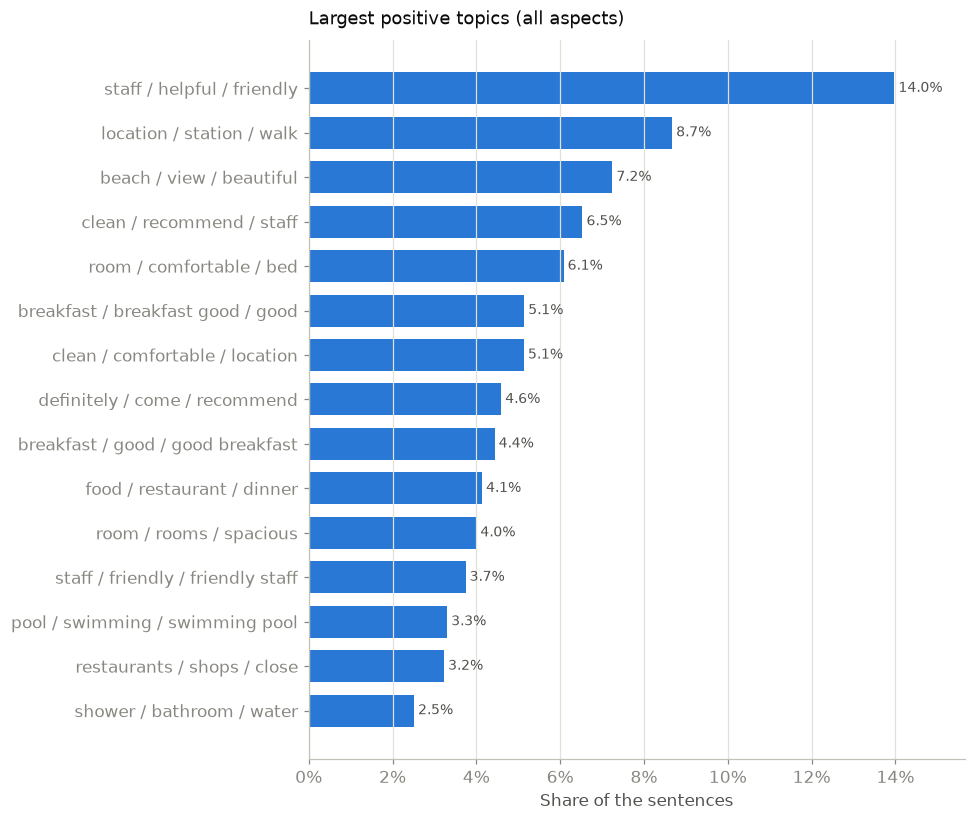

In [16]:
# HU: Áttekintő témamodell az összes ilyen mondaton (mintán) — aspektustól függetlenül.
# EN: Overview topic model on all such sentences (on a sample) — independent of the aspect.
rng = np.random.default_rng(CFG.random_seed)
overview_rows = np.sort(rng.choice(len(subset), size=min(30_000, len(subset)), replace=False))
overview = tm.fit_topics(subset["sentence"].iloc[overview_rows], embeddings[overview_rows])
display(pd.Series(overview.metrics).to_frame("value"))
display(overview.topic_info.head(20))
ev.save_table(overview.topic_info, f"05_{TAG}_topics_overview")
tm.plot_topic_sizes(overview.topic_info, f"Largest {SENTIMENT} topics (all aspects)", sentiment=SENTIMENT,
                    save_as=f"05_{TAG}_topics_overview"); plt.show()

### Finomság-vizsgálat / Granularity sweep

HU: Hány altémára bontsunk egy aspektust? A tapasztalat (v1, v2): egyetlen globális fürtméret nem jó minden
aspektusra — 1%-nál 19–21 apró, egymást átfedő altéma lett (pl. „rooms are small” és „the room was quite small” két
külön fürt), 3%-nál a fürdőszoba 18-ról **2** altémára ugrott (a HDBSCAN egy óriásfürtöt választott). Ezért (v3):
**finom fürtözés, majd a leghasonlóbb altémák összevonása** (BERTopic „topic reduction” elve), amíg legfeljebb
`CFG.subtopic_max_topics` marad, és nincs két `CFG.subtopic_merge_similarity` feletti hasonlóságú (közel-duplikátum)
téma. Az összevonás **átlagos kapcsolással** történik, és egy összevont altéma legfeljebb az aspektus
`CFG.subtopic_max_topic_share` részét (35%) teheti ki — enélkül (v3) „hógolyó” gyűjtőtémák keletkeztek (a zajnál a
forgalom, a zene és a szomszédok egyetlen 55%-os témává olvadt). A táblázat a három legnagyobb aspektuson mutatja a
lehetőségeket (`none` = nincs összevonás). Cél: kb.
**5–10 altéma**, a legnagyobb ≲ 50%, a koherencia (NPMI) ne romoljon. A UMAP aspektusonként egyszer fut (kb. 1–2 perc).

EN: How many subtopics should an aspect be split into? Experience (v1, v2): no single global cluster size suits every
aspect — at 1% there were 19–21 small, overlapping subtopics (e.g. "rooms are small" and "the room was quite small" as
two clusters), at 3% bathroom jumped from 18 to **2** subtopics (HDBSCAN picked one giant cluster). Hence (v3):
**fine clustering, then merging the most similar subtopics** (BERTopic "topic reduction" principle) until at most
`CFG.subtopic_max_topics` remain and no two topics exceed `CFG.subtopic_merge_similarity` (near-duplicates). The table
uses **average linkage**, and a merged subtopic may not exceed `CFG.subtopic_max_topic_share` (35%) of the aspect —
without that (v3) "snowball" catch-all topics appeared (for noise, traffic, music and neighbours melted into one 55%
topic). The table shows the options on the three largest aspects (`none` = no merging). Goal: about **5–10 subtopics**, largest ≲ 50%,
no worse coherence (NPMI). UMAP runs once per aspect (about 1–2 min). Set `RUN_SWEEP = False` once the setting is chosen.

In [17]:
RUN_SWEEP = True
if RUN_SWEEP:
    flag_counts = {a: int(subset[f"asp_{a}"].sum()) for a in ASPECT_NAMES if a not in ("generic",)}
    sweep_aspects = sorted(flag_counts, key=flag_counts.get, reverse=True)[:3]
    sweeps = []
    for aspect in sweep_aspects:
        rows = np.where(subset[f"asp_{aspect}"].to_numpy() == 1)[0]
        rows = np.sort(np.random.default_rng(CFG.random_seed).choice(
            rows, size=min(len(rows), CFG.topic_sample_per_aspect), replace=False))
        sweeps.append(tm.granularity_sweep(subset["sentence"].iloc[rows], embeddings[rows])
                        .reset_index().assign(aspect=aspect))
    sweep = pd.concat(sweeps, ignore_index=True).set_index(["aspect", "min_cluster_share", "max_topics"])
    display(sweep); ev.save_table(sweep, f"05_{TAG}_granularity_sweep")
print("Chosen subtopic settings:", tm.subtopic_params())

c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
14:54:08 | INFO    | src.topic_modeling | Topics: 19 | noise 27.0% -> 2.5% | NPMI 0.015 | diversity 0.668
14:54:12 | INFO    | src.topic_modeling | Topics: 12 | noise 27.0% -> 2.5% | NPMI -0.005 | diversity 0.683
14:54:17 | INFO    | src.topic_modeling | Topics: 10 | noise 27.0% -> 2.5% | NPMI 0.057 | diversity 0.660
14:54:21 | INFO    | src.topic_modeling | Topics: 8 | noise 27.0% -> 2.5% | NPMI 0.039 | diversity 0.688
14:54:25 | INFO    | src.topic_modeling | Topics: 6 | noise 27.0% -> 2.5% | NPMI 0.057 | diversity 0.767
14:54:29 | INFO    | src.topic_modeling | Topics: 9 | noise 24.1% -> 2.8% | NPMI 0.047 | diversity 0.678
14:54:34 | INFO    | src.topic_modeling | Topics: 9 | noise 24.1% -> 2.8% | NPMI 0.047 | diversity 0.678
14:54:38 | INFO    | src.topic_modeling | Topics:

min_cluster_size  n_topics_before_merge  n_topics  noise_share_before  mean_coherence_npmi  topic_diversity  largest_topic_share
aspect   min_cluster_share max_topics                                                                                                                                  
location 0.01              none                     150                     19        19              0.2701               0.0152           0.6684               0.1259
                           12                       150                     19        12              0.2701              -0.0054           0.6833               0.2000
                           10                       150                     19        10              0.2701               0.0573           0.6600               0.2154
                           8                        150                     19         8              0.2701               0.0387           0.6875               0.2154
                           6                        150                     19         6              0.2701               0.0572           0.7667               0.3262
         0.02              none                     300                      9         9              0.2405               0.0469           0.6778               0.3105
                           12                       300                      9         9              0.2405               0.0469           0.6778               0.3105
                           10                       300                      9         9              0.2405               0.0469           0.6778               0.3105
                           8                        300                      9         8              0.2405               0.0592           0.6875               0.3105
                           6                        300                      9         6              0.2405               0.0896           0.6500               0.3393
staff    0.01              none                     128                     22        22              0.2416              -0.0237           0.6318               0.1195
                           12                       128                     22        12              0.2416              -0.0361           0.7000               0.2716
                           10                       128                     22        10              0.2416              -0.0137           0.7000               0.2716
                           8                        128                     22         8              0.2416              -0.0154           0.7125               0.2716
                           6                        128                     22         6              0.2416              -0.0216           0.7167               0.2716
         0.02              none                     256                      3         3              0.0463               0.0077           0.6333               0.7616
                           12                       256                      3         2              0.0463               0.0220           0.8000               0.7616
                           10                       256                      3         2              0.0463               0.0220           0.8000               0.7616
                           8                        256                      3         2              0.0463               0.0220           0.8000               0.7616
                           6                        256                      3         2              0.0463               0.0220           0.8000               0.7616
room     0.01              none                      99                     31        31              0.2811              -0.0995           0.6129               0.0904
                           12                        99                     31        12              0.2811              -0.0331           0.6667               0.3226
       

14:56:28 | INFO    | src.evaluation | Table saved: 05_positive_v4_granularity_sweep.csv


Chosen subtopic settings: {'min_cluster_share': 0.02, 'max_topics': 10, 'merge_similarity': 0.9, 'max_topic_share': 0.35}


14:56:45 | INFO    | src.topic_modeling | room             9996 sentences (model fitted on 9996)
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
14:57:17 | INFO    | src.topic_modeling | Topics: 10 | noise 26.4% -> 1.2% | NPMI 0.003 | diversity 0.520
14:57:17 | INFO    | src.topic_modeling | location         16130 sentences (model fitted on 15000)
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
14:57:42 | INFO    | src.topic_modeling | Topics: 9 | noise 24.1% -> 2.8% | NPMI 0.047 | diversity 0.678
14:57:42 | INFO    | src.topic_modeling | staff            12842 sentences (model fitted on 12842)
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Li

,n_sentences,n_topics_before_merge,n_topics,min_cluster_size,noise_share_before,noise_share_after,mean_coherence_npmi,topic_diversity
aspect,,,,,,,,
room,9996,17,10,199,0.2638,0.0124,0.0026,0.5200
location,15000,9,9,300,0.2405,0.0275,0.0469,0.6778
staff,12842,3,2,256,0.0463,0.0065,0.0220,0.8000
cleanliness,7502,10,9,150,0.0953,0.0023,-0.0368,0.6778
facilities,4923,18,10,98,0.2216,0.0232,-0.0286,0.8300
comfort,7494,20,10,149,0.2036,0.0045,-0.0327,0.5700
breakfast,6371,3,3,127,0.0896,0.0003,-0.0062,0.8333
bathroom,1856,2,2,40,0.0000,0.0000,0.0783,1.0000
noise,1620,11,10,40,0.2074,0.0025,-0.0671,0.6400


15:01:37 | INFO    | src.evaluation | Table saved: 05_positive_v4_subtopic_quality.csv
15:01:37 | INFO    | src.evaluation | Table saved: 05_positive_v4_subtopics.csv


Main aspects: ['location', 'staff', 'room', 'cleanliness', 'comfort', 'breakfast', 'facilities', 'bed', 'view', 'value_for_money', 'bathroom', 'beach', 'reception', 'noise', 'pool', 'restaurant', 'parking', 'bar', 'wifi']


15:01:45 | INFO    | src.evaluation | Figure saved: 05_positive_v4_subtopics_by_aspect.png


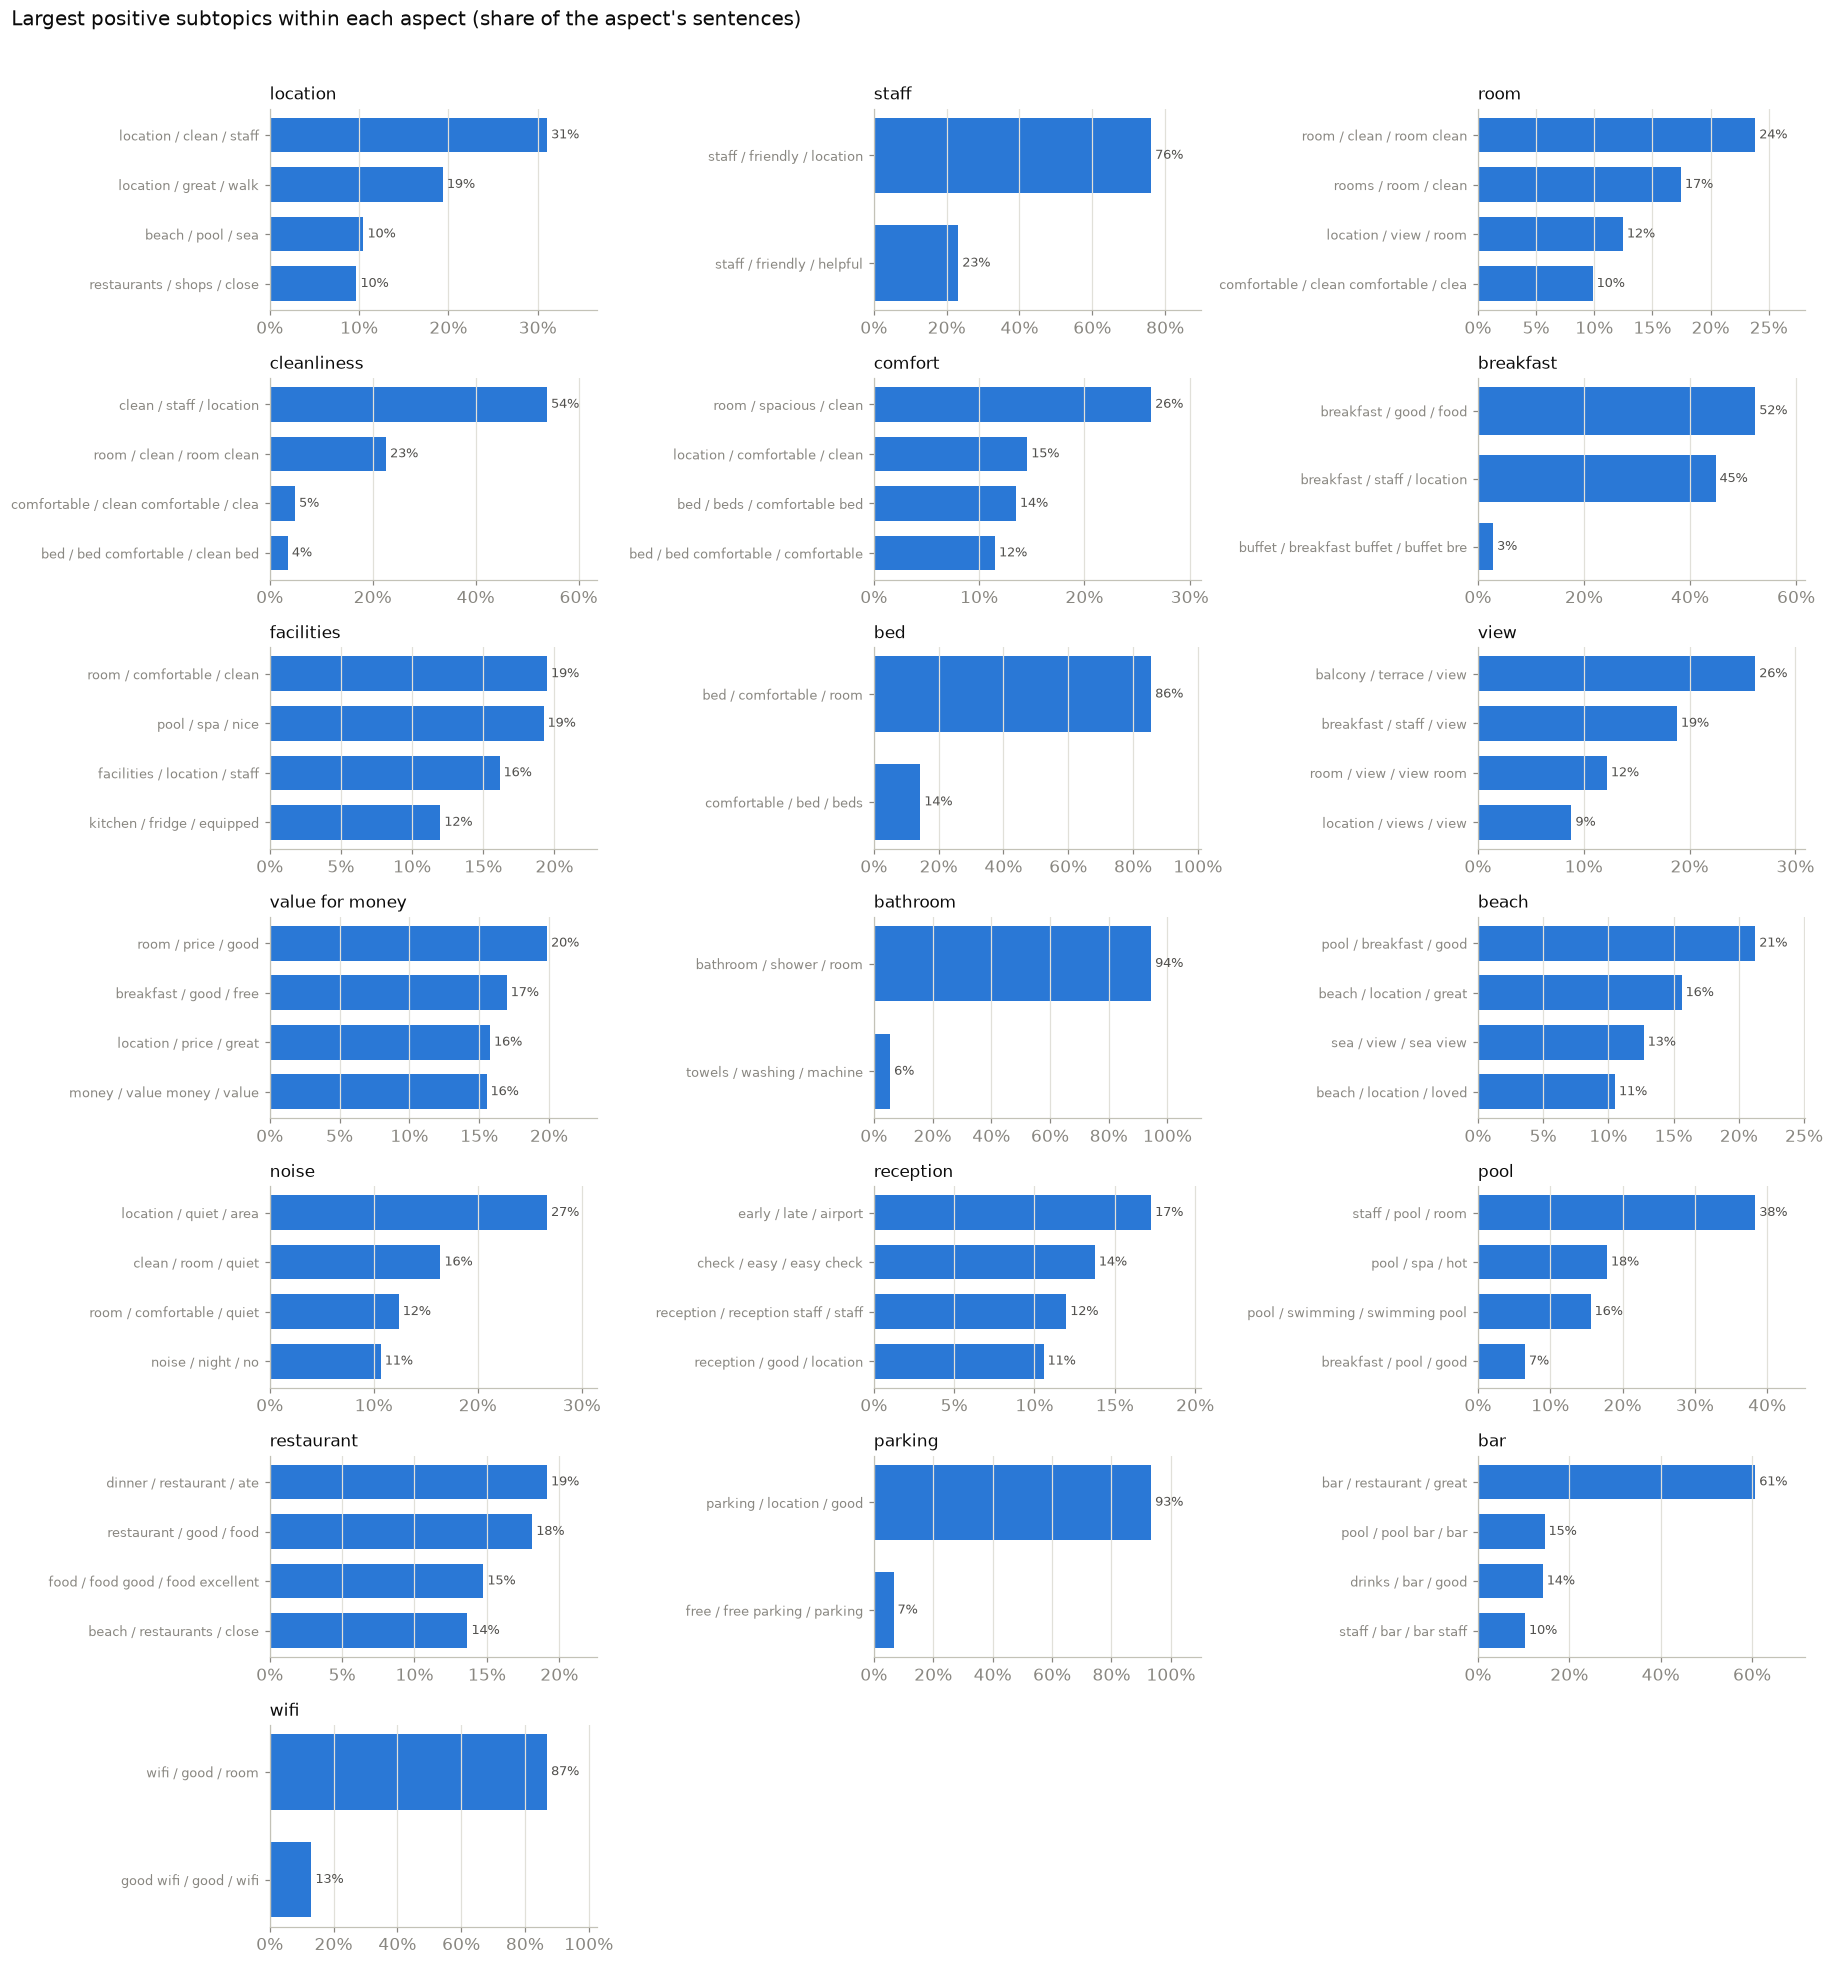

In [18]:
topic_table, assignments, topic_summary = tm.fit_subtopics_per_aspect(subset, embeddings, ASPECT_NAMES)
display(topic_summary)
ev.save_table(topic_summary, f"05_{TAG}_subtopic_quality")
# HU: A legtöbb mondatú, legalább egy altémát adó aspektusok. / EN: Aspects with most sentences and at least one subtopic.
MAIN_ASPECTS = (topic_summary[topic_summary["n_topics"] > 0]
                .sort_values("n_sentences", ascending=False).index.tolist())
print("Main aspects:", MAIN_ASPECTS)
ev.save_table(topic_table, f"05_{TAG}_subtopics")
dl.write_frame(assignments.assign(review_id=subset["review_id"].iloc[assignments["row"]].to_numpy(),
                                  sentence=subset["sentence"].iloc[assignments["row"]].to_numpy()),
               PATHS.labels / f"subtopic_assignments_{TAG}")

tm.plot_aspect_subtopics(topic_table, top_k=4, sentiment=SENTIMENT,
                         save_as=f"05_{TAG}_subtopics_by_aspect"); plt.show()

In [19]:
# HU: Olvasd el az altémákat a példamondatokkal! / EN: Read the subtopics with the example sentences!
for aspect in MAIN_ASPECTS[:4]:
    print(f"\n=== {aspect} ===")
    for _, r in topic_table[topic_table["aspect"] == aspect].head(6).iterrows():
        print(f"  [{r['topic']}] {r['label']}  ({r['share_within_aspect']:.0%}, NPMI {r['coherence_npmi']:.2f})")
        if r["merged_from"]:
            print(f"       merged from: {r['merged_from'][:150]}")
        print(f"       e.g. {r['examples'].split(' || ')[0][:150]}")


=== location ===
  [0] location / clean / staff  (31%, NPMI 0.17)
       e.g. Great location, large rooms, clean and friendly staff
  [1] location / great / walk  (19%, NPMI -0.02)
       e.g. Great location for getting around the city
  [2] beach / pool / sea  (10%, NPMI 0.05)
       e.g. The location is fantastic and close to the Beach
  [3] restaurants / shops / close  (10%, NPMI 0.08)
       e.g. Great location close to bars, restaurants and street food
  [4] located / location / good  (8%, NPMI -0.00)
       e.g. The location of the hotel is great
  [5] station / train / train station  (8%, NPMI 0.17)
       e.g. Great location within few minutes walk to the train station

=== staff ===
  [0] staff / friendly / location  (76%, NPMI 0.09)
       e.g. Great location, friendly staff, breakfast was great and rooms were very clean
  [1] staff / friendly / helpful  (23%, NPMI -0.05)
       merged from: staff / helpful / friendly + staff / friendly / helpful
       e.g. The staff was he

In [20]:
# HU: OPCIONÁLIS: beszédes nevek a dolgozatba (a témaszámokat a fenti listából vedd).
# EN: OPTIONAL: meaningful names for the thesis (take the topic numbers from the list above).
TOPIC_NAMES = {
    # ("bathroom", 0): "no hot water",
    # ("noise", 1): "thin walls / neighbours",
}
if TOPIC_NAMES:
    topic_table, assignments = tm.rename_topics(topic_table, assignments, TOPIC_NAMES)
    ev.save_table(topic_table, f"05_{TAG}_subtopics")

### Stabilitás / Stability

HU: Ugyanaz a modell három különböző véletlen kezdőértékkel a három legnagyobb aspektuson. A korrigált Rand-index
(ARI) 0,5 felett azt jelzi, hogy a témák nem a véletlen termékei.
EN: The same model with three different random seeds on the three largest aspects. An adjusted Rand index (ARI)
above 0.5 shows that the topics are not products of chance.

In [21]:
stability_rows = []
for aspect in MAIN_ASPECTS[:3]:
    rows = np.where(subset[f"asp_{aspect}"].to_numpy() == 1)[0]
    rows = np.sort(np.random.default_rng(CFG.random_seed).choice(
        rows, size=min(len(rows), CFG.topic_sample_per_aspect), replace=False))
    table = tm.topic_stability(subset["sentence"].iloc[rows], embeddings[rows], **tm.subtopic_params())
    stability_rows.append({"aspect": aspect, "mean_pairwise_ari": table.attrs["mean_pairwise_ari"],
                           "n_topics_per_seed": table["n_topics"].tolist()})
stability = pd.DataFrame(stability_rows).set_index("aspect").round(3)
display(stability); ev.save_table(stability, f"05_{TAG}_subtopic_stability")

c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
15:04:05 | INFO    | src.topic_modeling | Topics: 9 | noise 24.1% -> 2.8% | NPMI 0.047 | diversity 0.678
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
15:04:31 | INFO    | src.topic_modeling | Topics: 10 | noise 25.4% -> 3.0% | NPMI 0.047 | diversity 0.720
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
15:04:56 | INFO    | src.topic_modeling | Topics: 10 | noise 31.4% -> 3.2% | NPMI 0.059 | diversity 0.700
15:04:56 | INFO    | src.topic_modeling | Stabi

,mean_pairwise_ari,n_topics_per_seed
aspect,,
location,0.736,"[9, 10, 10]"
staff,0.966,"[2, 2, 2]"
room,0.748,"[10, 10, 10]"


15:07:33 | INFO    | src.evaluation | Table saved: 05_positive_v4_subtopic_stability.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/05_positive_v4_subtopic_stability.csv')

## 5. Panasztérkép / Complaint map

HU: Egy aspektus altémáinak aránya szegmensenként, liftként: 1 felett az altéma az adott szegmensben gyakoribb,
mint átlagosan. Például: a szállodákban a „vékony fal” vagy az apartmanokban a „nincs meleg víz” a jellemzőbb?
Minden cellára arány-z-próba (szegmens vs. többi) Benjamini–Hochberg-korrekcióval. `*` = szignifikáns ÉS legalább 20%-os
eltérés (|lift − 1| ≥ 0,2), halvány = nem. Kis szegmensben a nagy lift is lehet véletlen, nagy mintán pedig egy 1,06-os
eltérés is szignifikáns — a dolgozatban csak a csillagos cellákat értelmezd.
EN: Share of an aspect's subtopics per segment, as lift: above 1 the subtopic is more common in that segment than on
average. E.g.: is "thin walls" more typical in hotels, or "no hot water" in apartments?
A two-proportion z-test per cell (segment vs. rest) with Benjamini–Hochberg correction. `*` = significant AND at least a
20% difference (|lift − 1| ≥ 0.2), faded = not. In a small segment even a large lift can be chance, on a large sample even
1.06 is significant — interpret only the starred cells in the thesis.

15:07:52 | INFO    | src.evaluation | Table saved: 05_positive_v4_map_location_by_accommodation_type.csv


,segment,subtopic,lift,count,segment_n,q,significant,notable
58,Resort,beach / pool / sea,3.919,213,512,0.0000,True,True
37,Hostel,station / train / train station,1.708,75,547,0.0000,True,True
23,Bed and Breakfast,definitely / rome / trip,1.600,49,793,0.0011,True,True
31,Guest house,definitely / rome / trip,1.580,70,1147,0.0001,True,True
51,Motel,restaurants / shops / close,1.576,74,469,0.0001,True,True
50,Motel,beach / pool / sea,1.486,74,469,0.0005,True,True
15,Apartment,definitely / rome / trip,1.440,96,1726,0.0002,True,True
46,Hotel,airport / close airport / shuttle,1.431,555,8605,0.0000,True,True


15:07:55 | INFO    | src.evaluation | Figure saved: 05_positive_v4_map_location_by_accommodation_type.png


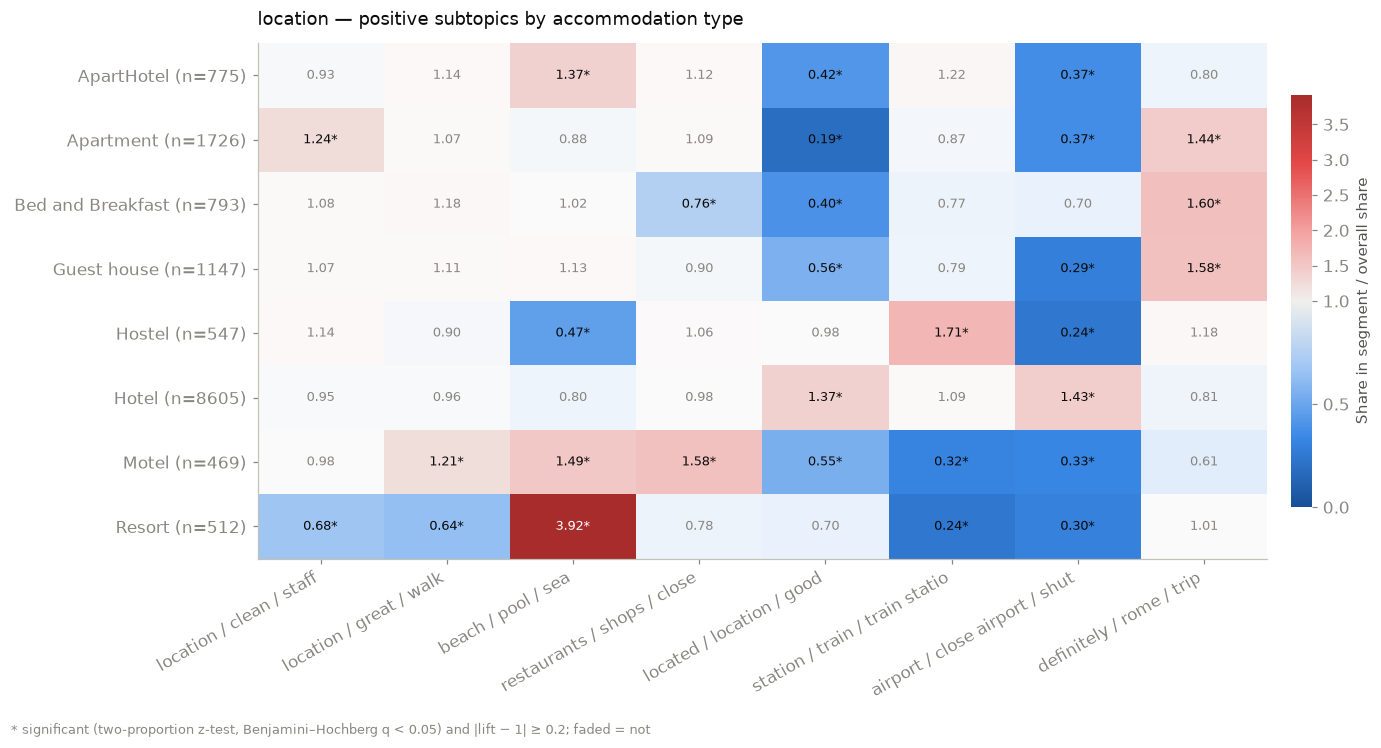

15:07:56 | INFO    | src.evaluation | Table saved: 05_positive_v4_map_location_by_accommodation_country.csv


,segment,subtopic,lift,count,segment_n,q,significant,notable
36,Japan,station / train / train station,3.019,124,491,0.0000,True,True
19,Greece,beach / pool / sea,2.876,175,623,0.0000,True,True
30,Italy,definitely / rome / trip,2.506,149,1398,0.0000,True,True
37,Japan,located / location / good,1.726,66,491,0.0000,True,True
34,Japan,restaurants / shops / close,1.596,78,491,0.0000,True,True
55,United Kingdom,airport / close airport / shuttle,1.565,162,2567,0.0000,True,True
12,France,station / train / train station,1.560,77,590,0.0001,True,True
43,Spain,beach / pool / sea,1.543,112,743,0.0000,True,True


15:07:59 | INFO    | src.evaluation | Figure saved: 05_positive_v4_map_location_by_accommodation_country.png


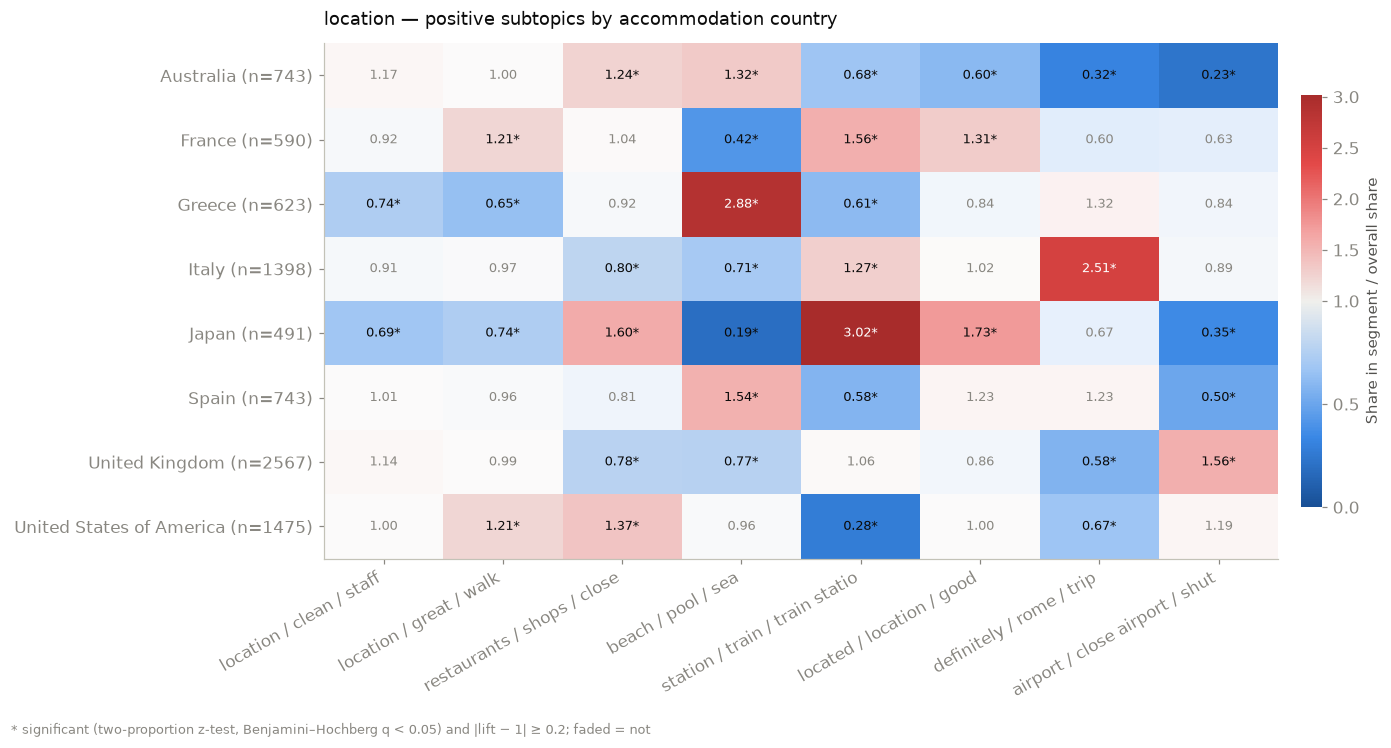

15:08:00 | INFO    | src.evaluation | Table saved: 05_positive_v4_map_staff_by_accommodation_type.csv


,segment,subtopic,lift,count,segment_n,q,significant,notable
11,Hotel,staff / friendly / helpful,1.211,2005,6927,0.0,True,True
2,Apartment,staff / friendly / location,1.201,879,962,0.0,True,True
7,Guest house,staff / friendly / helpful,0.592,151,1068,0.0,True,True
5,Bed and Breakfast,staff / friendly / helpful,0.579,131,947,0.0,True,True
3,Apartment,staff / friendly / helpful,0.361,83,962,0.0,True,True


15:08:01 | INFO    | src.evaluation | Figure saved: 05_positive_v4_map_staff_by_accommodation_type.png


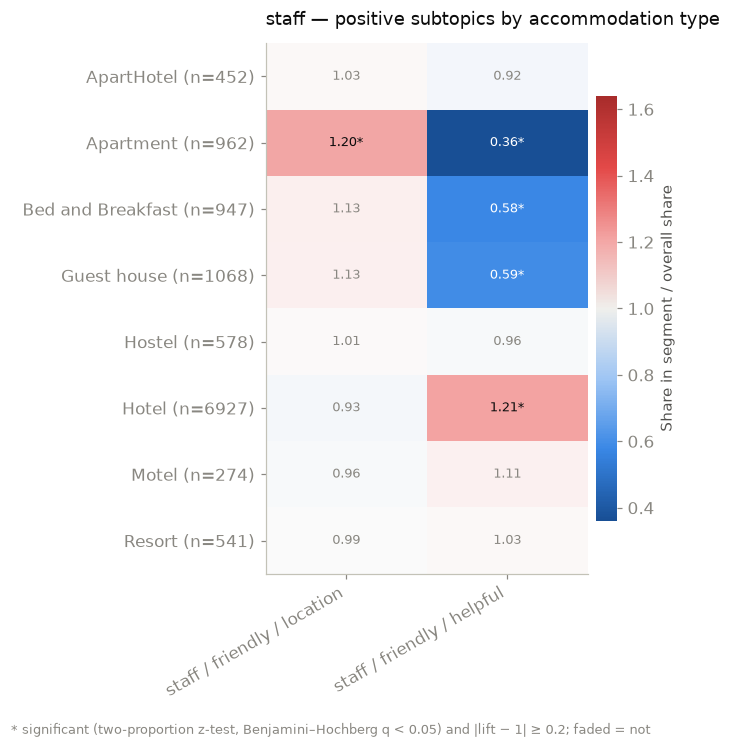

15:08:02 | INFO    | src.evaluation | Table saved: 05_positive_v4_map_staff_by_accommodation_country.csv


,segment,subtopic,lift,count,segment_n,q,significant,notable
15,United States of America,staff / friendly / helpful,1.320,365,1128,0.0000,True,True
3,France,staff / friendly / helpful,1.241,115,378,0.0118,True,True
5,Greece,staff / friendly / helpful,0.728,102,572,0.0004,True,True


15:08:03 | INFO    | src.evaluation | Figure saved: 05_positive_v4_map_staff_by_accommodation_country.png


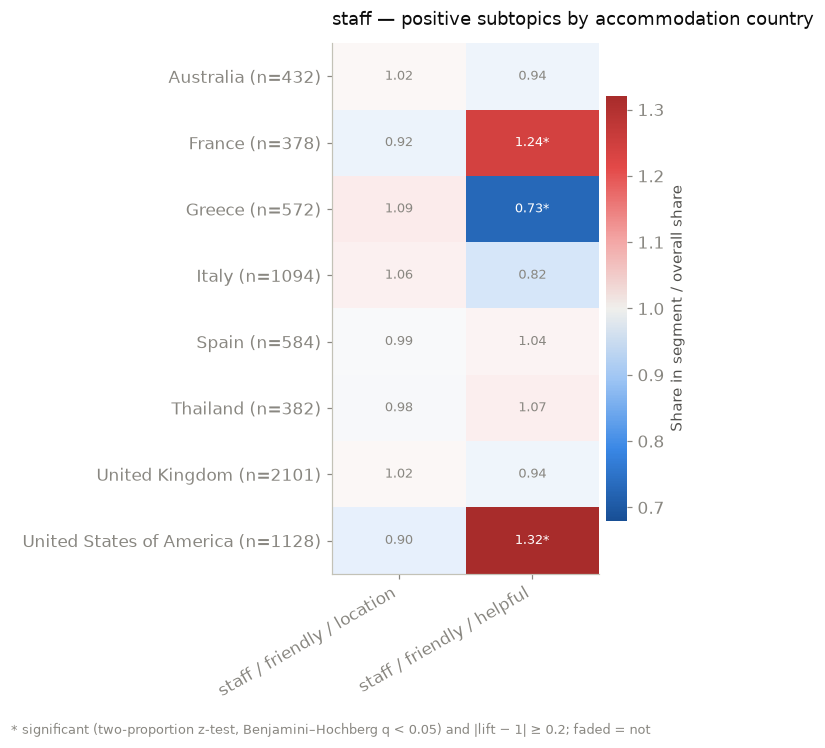

15:08:04 | INFO    | src.evaluation | Table saved: 05_positive_v4_map_room_by_accommodation_type.csv


,segment,subtopic,lift,count,segment_n,q,significant,notable
11,Apartment,comfortable / clean comfortable / clean,2.037,172,906,0.0000,True,True
20,Bed and Breakfast,breakfast / good / room,1.935,95,571,0.0000,True,True
51,Motel,comfortable / clean comfortable / clean,1.870,61,350,0.0000,True,True
58,Resort,location / view / room,1.690,66,311,0.0000,True,True
37,Hostel,bed / comfortable / beds,1.679,36,297,0.0029,True,True
47,Hotel,clean / comfortable / rooms,1.297,358,5534,0.0000,True,True
10,Apartment,location / view / room,1.265,144,906,0.0041,True,True
16,Bed and Breakfast,room / clean / room clean,1.203,164,571,0.0120,True,True


15:08:08 | INFO    | src.evaluation | Figure saved: 05_positive_v4_map_room_by_accommodation_type.png


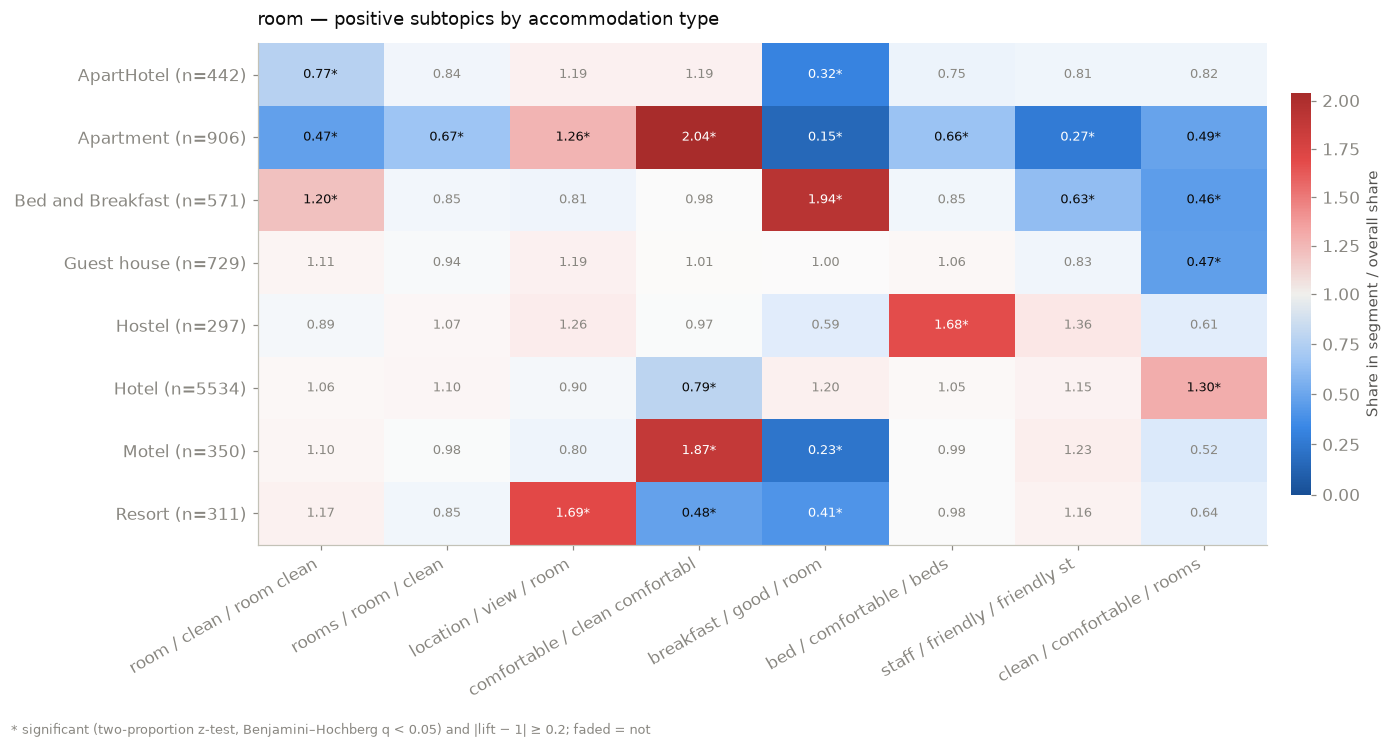

15:08:09 | INFO    | src.evaluation | Table saved: 05_positive_v4_map_room_by_accommodation_country.csv


,segment,subtopic,lift,count,segment_n,q,significant,notable
18,Greece,location / view / room,1.479,54,320,0.0140,True,True
42,Thailand,location / view / room,1.460,46,276,0.0284,True,True
34,Spain,location / view / room,1.437,61,372,0.0140,True,True
26,Italy,location / view / room,1.357,109,704,0.0036,True,True
3,Australia,comfortable / clean comfortable / clean,1.354,72,506,0.0271,True,True
52,United Kingdom,breakfast / good / room,1.347,219,2003,0.0000,True,True
16,Greece,room / clean / room clean,0.765,62,320,0.0434,True,True
50,United Kingdom,location / view / room,0.739,169,2003,0.0000,True,True


15:08:12 | INFO    | src.evaluation | Figure saved: 05_positive_v4_map_room_by_accommodation_country.png


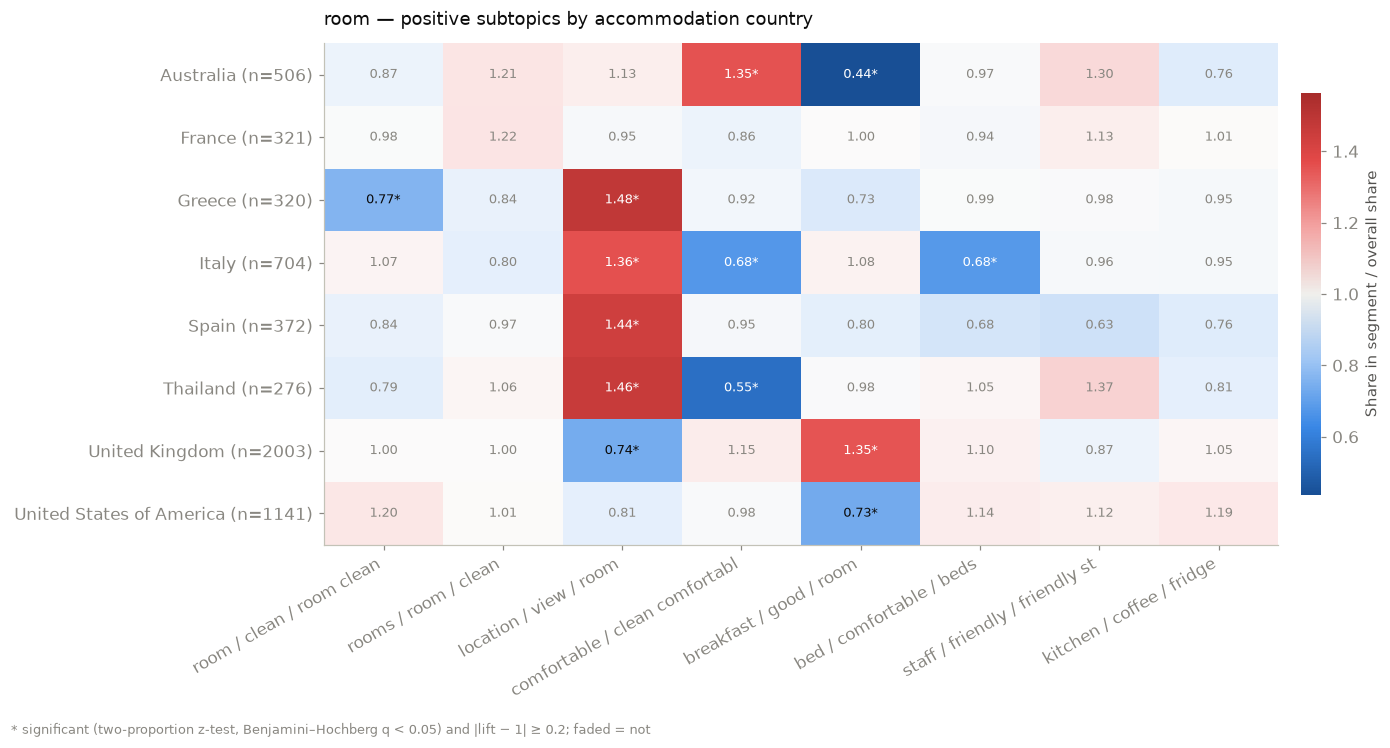

In [22]:
for aspect in MAIN_ASPECTS[:3]:
    for segment in ["accommodation_type", "accommodation_country"]:
        lift = tm.segment_table(assignments, subset, aspect, segment, min_count=50, top_segments=8)
        if lift.empty:
            continue
        long = tm.segment_long_table(lift)
        ev.save_table(long, f"05_{TAG}_map_{aspect}_by_{segment}")
        display(long[long["notable"]].head(8))
        tm.plot_segment_heatmap(lift, f"{aspect.replace('_', ' ')} — {SENTIMENT} subtopics by {segment.replace('_', ' ')}",
                                save_as=f"05_{TAG}_map_{aspect}_by_{segment}")
        plt.show()

## 6. Kézi ellenőrzés / Manual check

HU: Témánként 20 véletlen mondat Excelben; a `fits` oszlopba 1 (illik a témához) vagy 0 kerül. Az első futás
exportál, a kitöltés után a második futás kiszámolja a témánkénti pontosságot. (Kb. 1–2 óra a nagyobb aspektusokra.)
EN: 20 random sentences per topic in Excel; put 1 (fits the topic) or 0 into the `fits` column. The first run exports,
after filling it in the second run computes the per-topic precision. (About 1–2 hours for the larger aspects.)

In [23]:
check_file = PATHS.annotation / f"topic_check_{TAG}.xlsx"
if not check_file.exists():
    top_aspects = MAIN_ASPECTS[:4]
    tm.export_topic_check(topic_table[topic_table["aspect"].isin(top_aspects)],
                          assignments[assignments["aspect"].isin(top_aspects)], subset,
                          filename=check_file.name)
    print("Exported — fill in the 'fits' column, then re-run this cell.")
else:
    precision = tm.evaluate_topic_check(check_file.name)
    display(precision); ev.save_table(precision, f"05_{TAG}_topic_precision")

15:10:28 | INFO    | src.topic_modeling | Topic check exported: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\data\annotation\topic_check_positive_v4.xlsx (600 sentences)


Exported — fill in the 'fits' column, then re-run this cell.


In [24]:
# HU: Mennyire felsorolás a panasz és a dicséret? / EN: How list-like are complaints vs praise?
neg = sent.loc[sent["field_polarity"] == "negative", "sentence"]
pos = sent.loc[sent["field_polarity"] == "positive", "sentence"]
print(f"Complaint units with a comma: {neg.str.contains(',').mean():.1%}")
print(f"Praise units with a comma:    {pos.str.contains(',').mean():.1%}")
for t in neg[neg.str.contains(",")].sample(40, random_state=42):
    print("-", t[:160])

Complaint units with a comma: 20.1%
Praise units with a comma:    27.7%
- Well, the room was very small
- However, the room was still lovely just not what I was hoping for when I booked./
- Our room looked out onto an empty plot of land with various piles of rubbish on it, not the fault of the hotel
- Maby more sunbeds in the garden, they have 4 beds .in the afternoon always occupied
- Everything was amazing, nothing to complain
- However, the room size was small even for the 4 of us
- On December 23, around 5 pm, my original intended guest arrived
- Due to illness I had to leave a day early and was charged a cancellation fee, my room was already paid for up to Sunday so I thought that was a little unfair to
- I didn’t think it would be that bad) The included breakfast was also not great, not terrible
- Our apartment was on one of the high levels, and it made me feel a bit anxious to turn my back
- The communication moving up to the point of starting my stay, as we were a LITTLE unsure

In [25]:
for t in pos[pos.str.contains(",")].sample(40, random_state=42):
    print("-", t[:160])

- Very spacious room Quirky, vintage appeal 4 poster bed Easy parking
- Great location 5 mins walking distance via tunnel to the Gatwick terminal, comfortable clean room
- Peaceful country setting, plenty of space in the property
- The staff and spa, amazing!
- The rooms are ok, not big or fancy
- The hotel itself is located on the edge of the peninsula, which is great to go to the old city and around the lake
- Clean, quiet, perfectly located
- kitchen, bathroom, small dining area and a double bed
- The cottage was very clean, it had everything you would need in it for a City Break
- loved the location, tram station Molenwerf just few steps away
- My room was on the sea’s side, i enjoyed the sunset every morning from my balcony, it was indescribable
- The breakfasts were included in the price, and were substantial
- I did go at spring break so I expected partying and even then it's still peaceful there was a pool right in front of my door something i really liked no one had
- For fami

---
## Összefoglalás / Summary

| Kimenet / Output | Mire jó? / Purpose |
|---|---|
| `05_aspect_keyword_vs_model` (tábla + ábra) | **2/a mérése:** tanult modell vs. kulcsszólista, emberi címkén |
| `05_aspect_model_test_report` | aspektusonkénti precision / recall / F1 |
| `05_aspect_sentiment_model` | aspektus × szentiment a tanult aspektusokkal |
| `05_<sentiment>_<verzió>_removed_non_complaints` | kiszűrt nem-panasz egységek („nothing”, „all good”) |
| `05_<sentiment>_<verzió>_granularity_sweep` | az altéma-finomság (fürtméret × összevonás) választásának indoklása |
| `05_<sentiment>_<verzió>_subtopics` + `_subtopics_by_aspect.png` | **2/b:** altémák aspektusonként |
| `05_<sentiment>_<verzió>_subtopic_quality`, `_stability` | koherencia, diverzitás, stabilitás |
| `05_<sentiment>_<verzió>_map_*` | **panasztérkép** szegmensenként (a 8 legnagyobb altéma; db, lift, q, szignifikáns, jelentős) |
| `05_<sentiment>_<verzió>_topic_precision` | kézi ellenőrzés: témánkénti pontosság |

HU: A `<verzió>` = `CFG.topic_version` (most `v4`). A régebbi, verzió nélküli `05_negative_*` fájlok a v1 futás
eredményei — a dolgozat 3.4 fejezetében az előtte–utána összevetéshez hasznosak.
EN: `<verzió>` = `CFG.topic_version` (now `v4`). The older `05_negative_*` files without a version are the results of
run v1 — useful for the before/after comparison in chapter 3.4.